In [1]:
# Cell 1: Install dependencies
!pip install -q torch torchvision numpy matplotlib ipywidgets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 71.7 MB/s eta 0:00:00


1. Generating Arcade Gameplay Trajectories...
2. Training Visual Tokenizer (15 Epochs)...
   Epoch 5/15 - Loss: 0.00139
   Epoch 10/15 - Loss: 0.00025
   Epoch 15/15 - Loss: 0.00010


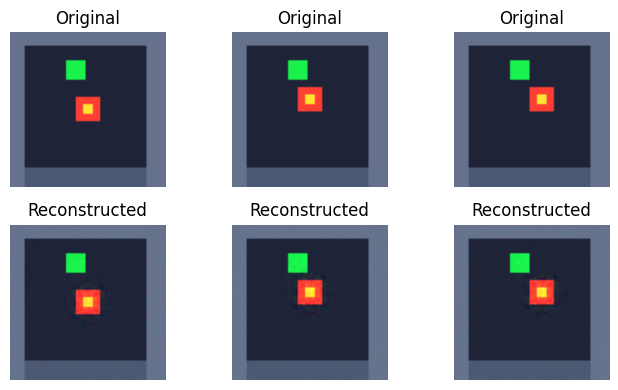

Tokenizer is ready!


In [8]:
# Complete Reset & Guaranteed Tokenizer (Runs in ~35 seconds)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Retro Game Environment with Walls & Floor (No pitch black void)
class ArcadeWorld:
    def __init__(self, size=64):
        self.size = size
        self.reset()

    def reset(self):
        self.player_x = 32.0
        self.player_y = 32.0
        self.target_x = float(np.random.randint(15, 49))
        self.target_y = float(np.random.randint(15, 49))
        return self.render()

    def step(self, action):
        speed = 4.0
        if action == 0: self.player_y = max(10.0, self.player_y - speed) # Up
        elif action == 1: self.player_y = min(48.0, self.player_y + speed) # Down
        elif action == 2: self.player_x = max(10.0, self.player_x - speed) # Left
        elif action == 3: self.player_x = min(48.0, self.player_x + speed) # Right
        return self.render()

    def render(self):
        # Dark navy game background
        canvas = np.full((self.size, self.size, 3), [0.12, 0.14, 0.22], dtype=np.float32)

        # Border walls & floor (Arcade stage)
        canvas[:6, :, :] = [0.4, 0.45, 0.55]      # Top wall
        canvas[56:, :, :] = [0.3, 0.35, 0.45]     # Floor
        canvas[:, :6, :] = [0.4, 0.45, 0.55]      # Left wall
        canvas[:, 56:, :] = [0.4, 0.45, 0.55]     # Right wall

        # Target (Bright Green Box)
        tx, ty = int(self.target_x), int(self.target_y)
        canvas[ty-4:ty+4, tx-4:tx+4] = [0.1, 0.95, 0.3]

        # Player (Bright Red/Yellow Hero)
        px, py = int(self.player_y), int(self.player_x)
        canvas[px-5:px+5, py-5:py+5] = [1.0, 0.25, 0.2]
        canvas[px-2:px+2, py-2:py+2] = [1.0, 0.9, 0.2] # Core highlight

        return canvas

# 2. Collect 4,000 transition frames
print("1. Generating Arcade Gameplay Trajectories...")
env = ArcadeWorld()
curr = env.reset()
f_t, acts, f_next = [], [], []

for _ in range(4000):
    a = random.randint(0, 3)
    nxt = env.step(a)
    f_t.append(curr)
    acts.append(a)
    f_next.append(nxt)
    curr = nxt

X_frames = torch.tensor(np.array(f_t)).permute(0, 3, 1, 2).float()
X_actions = torch.tensor(np.array(acts)).long()
Y_frames = torch.tensor(np.array(f_next)).permute(0, 3, 1, 2).float()

# 3. Vision Tokenizer WITHOUT Sigmoid saturation
class RobustTokenizer(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),  # 32x32
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), # 16x16
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),# 8x8
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 8 * 8),
            nn.Unflatten(1, (128, 8, 8)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1)
            # NO Sigmoid here -> Zero gradient death!
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return torch.clamp(self.decoder(z), 0.0, 1.0)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

tokenizer = RobustTokenizer(latent_dim=64).to(device)
optimizer = torch.optim.Adam(tokenizer.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(X_frames), batch_size=64, shuffle=True)

# 4. Train
print("2. Training Visual Tokenizer (15 Epochs)...")
tokenizer.train()
for epoch in range(15):
    total_loss = 0
    for (bx,) in loader:
        bx = bx.to(device)
        optimizer.zero_grad()
        out, _ = tokenizer(bx)
        loss = F.mse_loss(out, bx)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"   Epoch {epoch+1}/15 - Loss: {total_loss/len(loader):.5f}")

# 5. Display comparison
tokenizer.eval()
with torch.no_grad():
    sample = X_frames[:3].to(device)
    recon, _ = tokenizer(sample)

fig, axes = plt.subplots(2, 3, figsize=(7, 4))
for i in range(3):
    axes[0, i].imshow(sample[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy())
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()
print("Tokenizer is ready!")

In [9]:
# Cell 7: Train the World Model Dynamics
# 1. Convert all recorded images into latent vectors (Z-space)
tokenizer.eval()
with torch.no_grad():
    Z_t = tokenizer.encode(X_frames.to(device))
    Z_next = tokenizer.encode(Y_frames.to(device))

# 2. Dynamics Network (Residual Prediction)
class ActionDynamicsModel(nn.Module):
    def __init__(self, latent_dim=64, num_actions=4):
        super().__init__()
        self.action_embed = nn.Embedding(num_actions, 16)
        self.net = nn.Sequential(
            nn.Linear(latent_dim + 16, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

    def forward(self, z, action):
        a_emb = self.action_embed(action)
        inp = torch.cat([z, a_emb], dim=-1)
        # Residual step: z_next = z_current + delta
        return z + self.net(inp)

dynamics = ActionDynamicsModel(latent_dim=64, num_actions=4).to(device)
dyn_optimizer = torch.optim.Adam(dynamics.parameters(), lr=1e-3)
dyn_loader = DataLoader(TensorDataset(Z_t, X_actions.to(device), Z_next), batch_size=64, shuffle=True)

# 3. Train the Brain
print("Training Action Dynamics Brain...")
dynamics.train()
for epoch in range(25):
    total_loss = 0
    for z_curr, act, z_target in dyn_loader:
        dyn_optimizer.zero_grad()
        z_pred = dynamics(z_curr, act)
        loss = F.mse_loss(z_pred, z_target)
        loss.backward()
        dyn_optimizer.step()
        total_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/25 - Loss: {total_loss/len(dyn_loader):.6f}")

print("World Model Brain is ready to play!")

Training Action Dynamics Brain...
Epoch 5/25 - Loss: 0.008186
Epoch 10/25 - Loss: 0.002175
Epoch 15/25 - Loss: 0.001188
Epoch 20/25 - Loss: 0.000800
Epoch 25/25 - Loss: 0.000640
World Model Brain is ready to play!


In [10]:
# Cell 8: Playable Neural Simulation
import ipywidgets as widgets
from IPython.display import display, clear_output

# Start from a fresh rendered frame
env_test = ArcadeWorld()
initial_frame = env_test.reset()

# Convert initial frame to tensor and latent z
current_tensor = torch.tensor(initial_frame).permute(2, 0, 1).unsqueeze(0).float().to(device)
with torch.no_grad():
    current_z = tokenizer.encode(current_tensor)

output_box = widgets.Output()

def step_ai_world(action_id):
    global current_z
    dynamics.eval()
    tokenizer.eval()
    with torch.no_grad():
        # 1. Brain predicts next latent state from your button click
        action_tensor = torch.tensor([action_id]).long().to(device)
        current_z = dynamics(current_z, action_tensor)

        # 2. Vision Tokenizer decodes the imagined latent state back into an image
        imagined_frame = tokenizer.decode(current_z)

    # 3. Render hallucinated screen
    with output_box:
        clear_output(wait=True)
        img = imagined_frame[0].cpu().permute(1, 2, 0).numpy()
        plt.figure(figsize=(3.5, 3.5))
        plt.imshow(img)
        plt.title("Neural World Model (Hallucinated Live)")
        plt.axis("off")
        plt.show()

# Button handlers
btn_up = widgets.Button(description="⬆️ Up", layout=widgets.Layout(width='80px'))
btn_down = widgets.Button(description="⬇️ Down", layout=widgets.Layout(width='80px'))
btn_left = widgets.Button(description="⬅️ Left", layout=widgets.Layout(width='80px'))
btn_right = widgets.Button(description="➡️ Right", layout=widgets.Layout(width='80px'))

btn_up.on_click(lambda _: step_ai_world(0))
btn_down.on_click(lambda _: step_ai_world(1))
btn_left.on_click(lambda _: step_ai_world(2))
btn_right.on_click(lambda _: step_ai_world(3))

# Layout UI
ui = widgets.VBox([
    widgets.HBox([widgets.Label(value="", layout=widgets.Layout(width='80px')), btn_up]),
    widgets.HBox([btn_left, btn_down, btn_right]),
    output_box
])

display(ui)
# Render first frame
step_ai_world(0)

In [11]:
# Save model weights to download
torch.save(tokenizer.state_dict(), "tokenizer.pth")
torch.save(dynamics.state_dict(), "dynamics.pth")
print("Models saved! You can find 'tokenizer.pth' and 'dynamics.pth' in the Files tab on the left.")

Models saved! You can find 'tokenizer.pth' and 'dynamics.pth' in the Files tab on the left.
